# DSC 209R Project 1

#### Data: Grocery Store Foods
The foods stocked by grocery stores strongly influence consumer decisions and dietary health. Here, you will examine a dataset of over 50,000 food items sold by Walmart, Target, and Whole Foods that categorizes items based on their degree of processing, price range, and nutritional content.

The data has the following columns:
- `name`: The name of the food product.
- `store`: The store where the product is sold (Walmart, Target, or Whole Foods).
- `category`: The food category of the product.
- `brand`: The brand of the product.
- `FPro`: The Food Processing Score, a value between 0 (minimally processed) to 1 (highly processed), as calculated by the GroceryDB authors using a random forest model.
- `FPro_class`: The predicted NOVA classification for the food. 0 = Unprocessed or minimally processed foods; 1 = Processed culinary ingredients; 2 = Processed foods; 3 = Ultra-processed food and drink products.
- `price`: The price of the product.
- `price percal`: The price per calorie.
- `package_weight`: The weight of the package in grams.
- `Protein`: Protein content.
- `Total Fat`: Total fat content.
- `Carbohydrate`: Carbohydrate content.
- `Sugars, total`: Total sugar content.
- `Fiber, total dietary`: Dietary fiber content.
- `Sodium`: Sodium content.
- `Cholesterol`: Cholesterol content.

The nutrition data (protein, fat, carbs, sugar, fiber, sodium, and cholesterol) is normalized to grams per 100g of product.


## Load data

In [2]:
import numpy as np 
import pandas as pd 
from matplotlib import pyplot as plt 

In [3]:
d = pd.read_csv('grocerydb.csv')
d.shape

(26250, 16)

In [4]:
d.head()

,name,store,category,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
0,Stonyfield Organic Whole Milk Strawberry Beet ...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
1,Stonyfield Organic Whole Milk Pear Spinach Man...,Target,baby-food,Stonyfield,0.815250,3.0,5.29,0.043984,396.8930,5.050505,3.030303,12.121212,9.090909,0.000000,0.080808,0.010101
2,Once Upon a Farm Organic Mama Blueberry Fruit ...,Target,baby-food,Once Upon a Farm,0.583219,3.0,2.79,0.055973,90.7184,1.098901,0.549451,13.186813,7.692308,2.197802,0.010989,0.000000
3,Once Upon a Farm Organic Strawberry Kids&#39; ...,Target,baby-food,Once Upon a Farm,0.451056,0.0,2.49,0.019213,90.7184,5.494505,7.692308,15.384615,8.791209,3.296703,0.000000,0.000000
4,Horizon Organic Growing Years Strawberry Kids&...,Target,baby-food,DANNON,0.773519,3.0,4.99,0.017781,396.8930,3.030303,1.010101,14.141414,6.060606,2.020202,0.050505,0.005051


In [5]:
d.dtypes

name                        str
store                       str
category                    str
brand                       str
FPro                    float64
FPro_class              float64
price                   float64
price percal            float64
package_weight          float64
Protein                 float64
Total Fat               float64
Carbohydrate            float64
Sugars, total           float64
Fiber, total dietary    float64
Sodium                  float64
Cholesterol             float64
dtype: object

## Data cleaning

In [6]:
# count missing values 
d.isna().sum()

name                       0
store                      0
category                   0
brand                     69
FPro                       0
FPro_class                 0
price                   4030
price percal            5470
package_weight          1275
Protein                    0
Total Fat                  0
Carbohydrate               0
Sugars, total              9
Fiber, total dietary       9
Sodium                     0
Cholesterol                0
dtype: int64

Lots of missing prices, so analysis and visualizations on price might not be accruate.

## EDA

Look at very basic and simple charts to get an understanding of the data. 

In [7]:
# all unique food categories
d['category'].unique()

<StringArray>
[              'baby-food',                  'baking',
                   'bread',               'breakfast',
                   'cakes',                  'cereal',
                  'cheese',         'coffee-beans-wf',
         'cookies-biscuit',    'culinary-ingredients',
      'dairy-yogurt-drink',               'dressings',
            'drink-coffee',             'drink-juice',
          'drink-juice-wf',      'drink-shakes-other',
 'drink-soft-energy-mixes',               'drink-tea',
          'drink-water-wf',                 'eggs-wf',
       'ice-cream-dessert',                   'jerky',
              'mac-cheese',           'meat-packaged',
         'meat-poultry-wf',    'milk-milk-substitute',
          'muffins-bagels',           'nuts-seeds-wf',
           'pasta-noodles',  'pastry-chocolate-candy',
                   'pizza',   'prepared-meals-dishes',
        'produce-beans-wf',        'produce-packaged',
           'pudding-jello',    'rice-grains-package

A few different types of snakcs that can be used for comparison analysis.

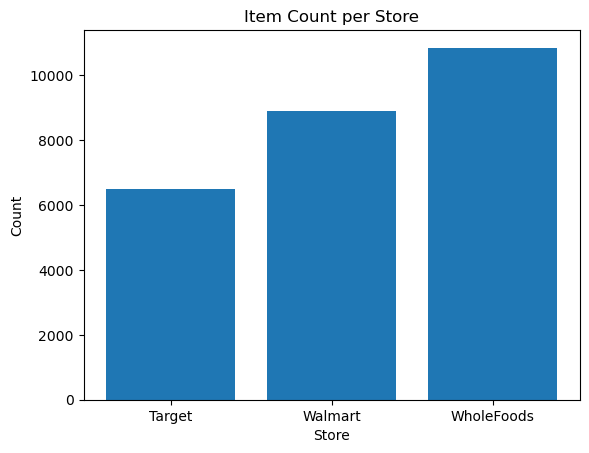

In [8]:
store_count = d.groupby('store').count().reset_index()
plt.bar(store_count['store'], store_count['name'])
plt.xlabel('Store')
plt.ylabel('Count')
plt.title('Item Count per Store')
plt.show()

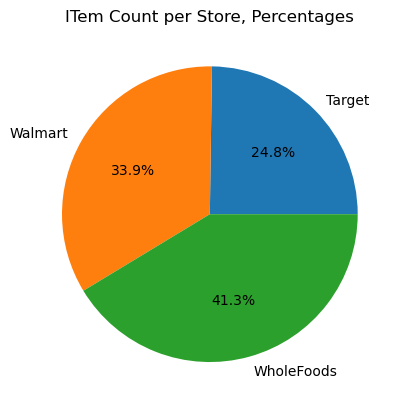

In [9]:
store_perc = store_count['name'] / d.shape[0]
plt.pie(store_perc, labels=store_count['store'], autopct='%1.1f%%')
plt.title('ITem Count per Store, Percentages')
plt.show()

## Better graphs

In [10]:
# average price for each category of food
cat_store_price = d.groupby(by=['category', 'store']).mean(numeric_only=True).reset_index()[['store', 'category', 'price']]
cat_store_price.head()

,store,category,price
0,Target,baby-food,4.170000
1,Walmart,baby-food,2.587273
2,WholeFoods,baby-food,2.350952
3,Target,baking,3.173571
4,Walmart,baking,2.636828


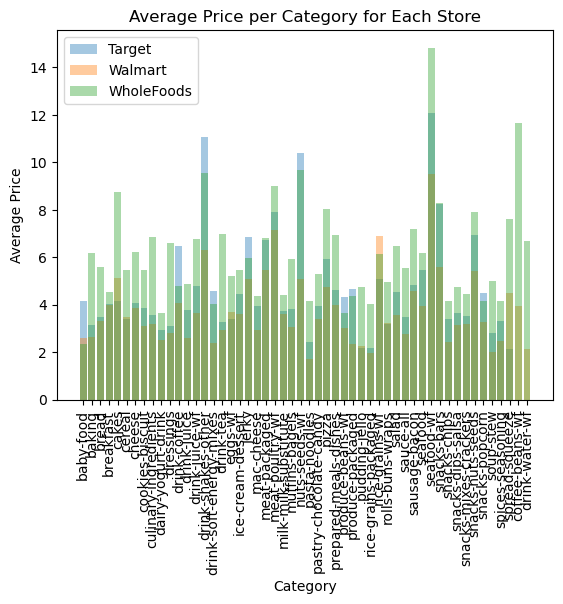

In [11]:
plt.bar(data=cat_store_price[cat_store_price['store']=='Target'], x='category', height='price', label='Target', alpha=0.4)
plt.bar(data=cat_store_price[cat_store_price['store']=='Walmart'], x='category', height='price', label='Walmart', alpha=0.4)
plt.bar(data=cat_store_price[cat_store_price['store']=='WholeFoods'], x='category', height='price', label='WholeFoods', alpha=0.4)
plt.legend()
plt.xlabel('Category')
plt.ylabel('Average Price')
plt.xticks(rotation=90)
plt.title('Average Price per Category for Each Store')
plt.show()

In [12]:
# dataset by store
target = d[d['store']=='Target']
walmart = d[d['store']=='Walmart']
wf = d[d['store']=='WholeFoods']

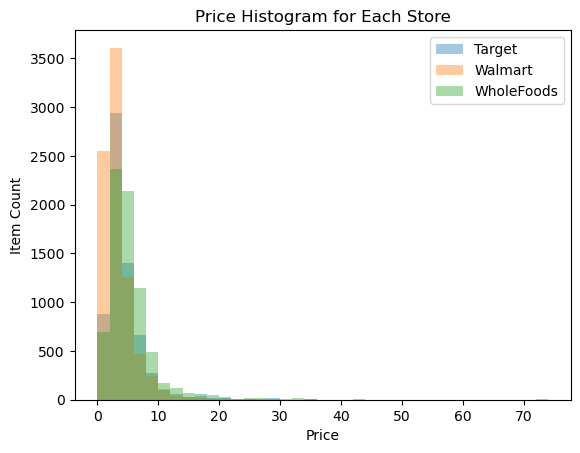

In [13]:
# price histogram, not grouped by category, only by store
bin_width = 2
bin_edges = np.arange(min(d['price']), max(d['price']) + bin_width, bin_width)

plt.hist(x=target['price'], bins=bin_edges, label='Target', alpha=0.4)
plt.hist(x=walmart['price'], bins=bin_edges, label='Walmart', alpha=0.4)
plt.hist(x=wf['price'], bins=bin_edges, label='WholeFoods', alpha=0.4)
plt.legend()
plt.xlabel('Price')
plt.ylabel('Item Count')
plt.title('Price Histogram for Each Store')
plt.show()

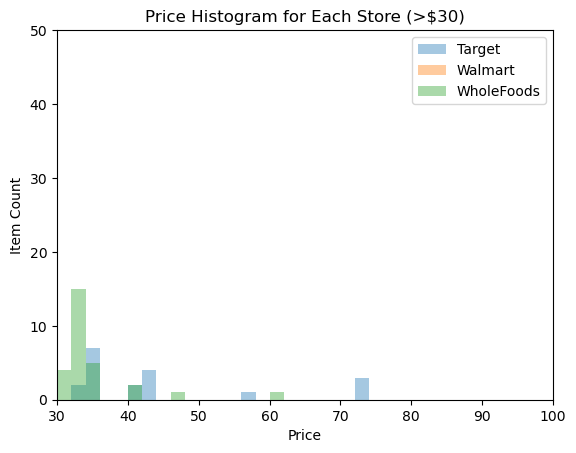

In [14]:
# zoom in on items over 30
plt.hist(x=target['price'], bins=bin_edges, label='Target', alpha=0.4)
plt.hist(x=walmart['price'], bins=bin_edges, label='Walmart', alpha=0.4)
plt.hist(x=wf['price'], bins=bin_edges, label='WholeFoods', alpha=0.4)
plt.legend()
plt.xlabel('Price')
plt.ylabel('Item Count')
plt.title('Price Histogram for Each Store (>$30)')
plt.xlim([30, 100])
plt.ylim([0,50])
plt.show()

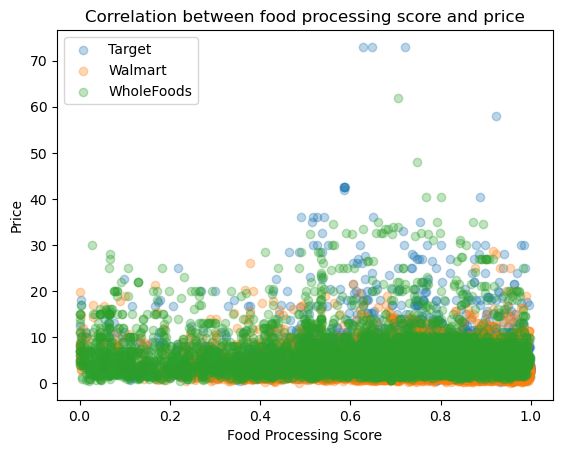

In [15]:
# does food processing score have any correlation with the price?
plt.scatter(target['FPro'], target['price'], alpha=0.3, label='Target')
plt.scatter(walmart['FPro'], walmart['price'], alpha=0.3, label='Walmart')
plt.scatter(wf['FPro'], wf['price'], alpha=0.3, label='WholeFoods')
plt.legend(loc='upper left')
plt.title('Correlation between food processing score and price')
plt.xlabel('Food Processing Score')
plt.ylabel('Price')
plt.show()

In [16]:
target.groupby(['store','FPro_class']).count().reset_index()

,store,FPro_class,name,category,brand,FPro,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
0,Target,0.0,369,369,366,369,369,349,367,369,369,369,369,369,369,369
1,Target,1.0,60,60,60,60,60,57,59,60,60,60,60,60,60,60
2,Target,2.0,585,585,579,585,585,569,585,585,585,585,585,585,585,585
3,Target,3.0,5489,5489,5476,5489,5489,5370,5475,5489,5489,5489,5489,5489,5489,5489


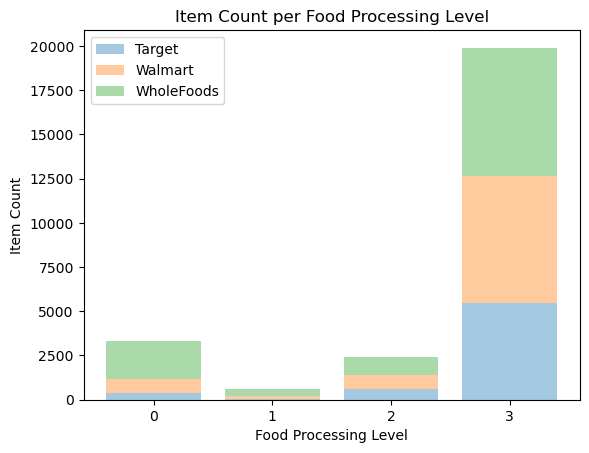

In [17]:
# does wholefoods really have less processed food?
fpro_class_labels = [0,1,2,3]
target_height = target.groupby('FPro_class').count().reset_index()['name']
walmart_height = walmart.groupby('FPro_class').count().reset_index()['name']
wf_height = wf.groupby('FPro_class').count().reset_index()['name']
plt.bar(fpro_class_labels, target_height, label='Target', alpha=0.4)
plt.bar(fpro_class_labels, walmart_height, label='Walmart', alpha=0.4, bottom=target_height)
plt.bar(fpro_class_labels, wf_height, label='WholeFoods', alpha=0.4, bottom=target_height+walmart_height)
plt.legend()
plt.xticks([0,1,2,3])
plt.xlabel('Food Processing Level')
plt.ylabel('Item Count')
plt.title('Item Count per Food Processing Level')
plt.show()

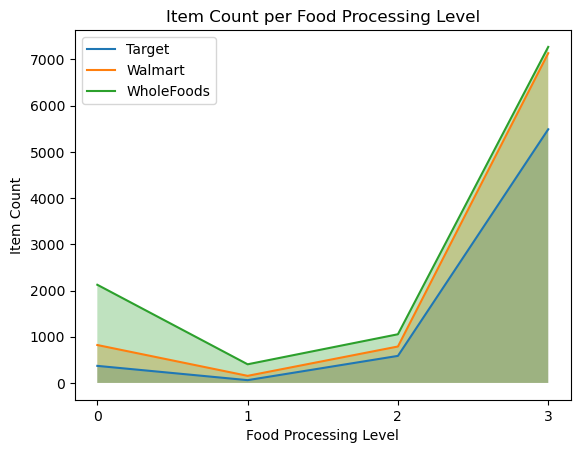

In [18]:
# does wholefoods really have less processed food?
fpro_class_labels = [0,1,2,3]
target_height = target.groupby('FPro_class').count().reset_index()['name']
walmart_height = walmart.groupby('FPro_class').count().reset_index()['name']
wf_height = wf.groupby('FPro_class').count().reset_index()['name']
plt.plot(fpro_class_labels, target_height, label='Target')
plt.fill_between(fpro_class_labels, target_height, alpha=0.3)
plt.plot(fpro_class_labels, walmart_height, label='Walmart')
plt.fill_between(fpro_class_labels, walmart_height, alpha=0.3)
plt.plot(fpro_class_labels, wf_height, label='WholeFoods')
plt.fill_between(fpro_class_labels, wf_height, alpha=0.3)
plt.legend()
plt.xticks([0,1,2,3])
plt.xlabel('Food Processing Level')
plt.ylabel('Item Count')
plt.title('Item Count per Food Processing Level')
plt.show()

WholeFoods does have more unprocessed food, but it also has more items in general.

In [19]:
# what brand has the highest price (on average)?
brands = d.groupby('brand').mean(numeric_only=True).reset_index()
brands.sort_values('price', ascending=False)

,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
2944,TB12 Sports,0.748722,3.0,47.990000,0.013435,952.543977,75.000000,6.250000,9.375000,0.000000,3.125000,1.093750,0.000000
910,Evo Hemp,0.602944,2.4,34.490000,0.012098,156.489240,19.919430,25.729264,40.253848,10.374703,10.374703,0.123666,0.000000
2218,One Brands,0.692889,3.0,32.280000,0.016784,540.908460,26.666667,15.555556,46.666667,2.222222,20.000000,0.422222,0.000000
2217,One Brand,0.771889,3.0,32.280000,0.016276,540.908460,26.666667,15.555556,46.666667,2.222222,17.777778,0.355556,0.000000
2457,READYWISE,0.763571,3.0,31.656667,0.009991,907.184740,3.115265,1.557632,83.136033,62.242991,14.226376,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3382,di stefano,0.582704,2.0,NaN,NaN,226.796000,14.109596,14.109596,3.527399,3.527399,0.000000,0.176370,0.052911
3387,gimMe,0.523222,3.0,NaN,NaN,22.963095,38.461538,0.000000,38.461538,0.000000,38.461538,0.192308,0.000000
3392,joyböl,0.880389,3.0,NaN,NaN,59.533950,19.166667,15.000000,58.333333,12.500000,7.500000,0.300000,0.000000
3393,kitchfix,0.691826,3.0,NaN,NaN,255.145500,2.352941,8.235294,31.176471,0.588235,1.764706,0.188235,0.041176


In [20]:
# does the same brand sell at different prices in different stores?

# filter for brands that are sold at all three stores
store_brands = d.groupby(['store', 'brand']).mean(numeric_only=True).reset_index()
brands_store_count = store_brands.groupby('brand').count().dropna(subset=['price'])
brands_all3 = brands_store_count[brands_store_count['store']==3].reset_index()['brand']
brands_all3

0              Banza
1         Bear Naked
2      Birch Benders
3            Biscoff
4     Bob's Red Mill
           ...      
72           Walkers
73              Wasa
74       Wild Planet
75          YumEarth
76           siggi's
Name: brand, Length: 77, dtype: str

In [21]:
brands_store_count[brands_store_count['store']>=3]

,store,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
brand,,,,,,,,,,,,,
Banza,3,3,3,3,3,3,3,3,3,3,3,3,3
Bear Naked,3,3,3,3,3,3,3,3,3,3,3,3,3
Birch Benders,3,3,3,3,3,3,3,3,3,3,3,3,3
Biscoff,3,3,3,3,3,3,3,3,3,3,3,3,3
Bob's Red Mill,3,3,3,3,3,3,3,3,3,3,3,3,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Walkers,3,3,3,3,3,3,3,3,3,3,3,3,3
Wasa,3,3,3,3,3,3,3,3,3,3,3,3,3
Wild Planet,3,3,3,3,3,3,3,3,3,3,3,3,3


In [22]:
store_brands[store_brands['store']=='Target'].sort_values('brand')

,store,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
0,Target,100 Grand,0.952667,3.000000,3.990000,0.002815,297.669750,4.761905,19.047619,71.428571,52.380952,0.000000,0.214286,0.023810
1,Target,1st National Bagel Company,0.874556,3.000000,1.790000,0.001656,403.980375,11.176471,0.735294,53.529412,7.058824,2.352941,0.426471,0.000000
2,Target,2's Company,0.879820,3.000000,3.990000,0.010053,99.223250,13.333333,4.444444,75.555556,0.000000,0.000000,0.700000,0.000000
3,Target,4Earth,0.335815,0.000000,3.990000,NaN,226.796000,1.176471,0.000000,9.411765,5.882353,3.529412,0.000000,0.000000
4,Target,8 Myles,0.775667,3.000000,4.490000,0.010843,226.796000,7.709251,8.370044,19.162996,4.625551,0.881057,0.189427,0.028634
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,Target,innofoods,0.727417,2.500000,6.790000,0.007309,170.097000,10.582197,38.801390,44.092488,24.691794,8.818498,0.176370,0.000000
959,Target,popchips,0.970639,3.000000,3.490000,0.005593,141.747500,7.054798,14.991446,70.547981,5.291099,3.527399,0.670206,0.000000
960,Target,purely elizabeth.,0.758722,3.000000,2.590000,0.020380,56.699000,18.965517,24.137931,51.724138,5.172414,10.344828,0.198276,0.000000
961,Target,siggi's,0.634752,3.000000,1.573333,0.038163,137.495075,9.791602,1.800000,8.992722,6.638659,0.000000,0.039860,0.011328


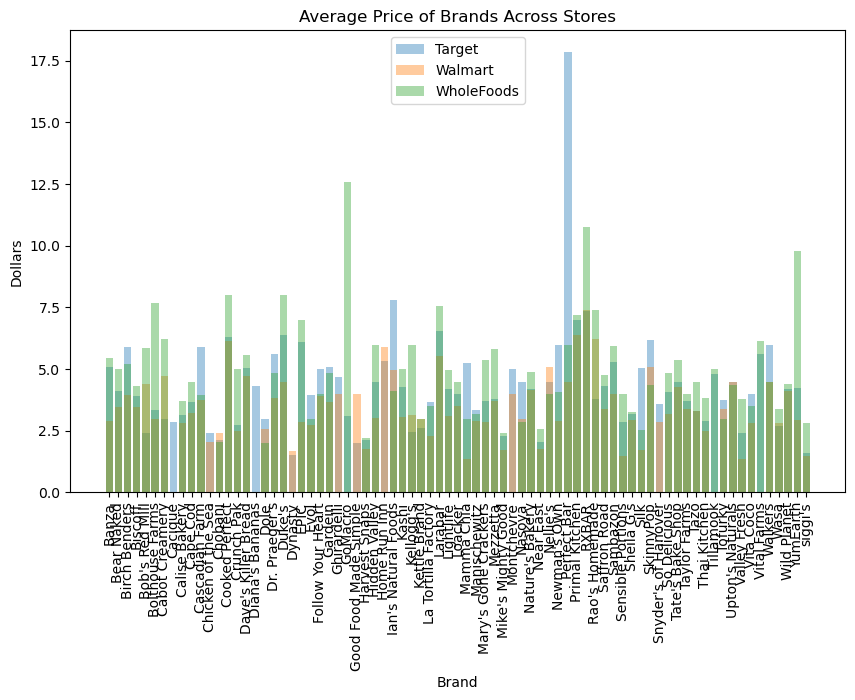

In [23]:
brand_all3_meanprice = d[d['brand'].isin(brands_all3)].groupby(['store', 'brand']).mean(numeric_only=True).reset_index()
target_brand_mp = brand_all3_meanprice[brand_all3_meanprice['store']=='Target']
walmart_brand_mp = brand_all3_meanprice[brand_all3_meanprice['store']=='Walmart']
wf_brand_mp = brand_all3_meanprice[brand_all3_meanprice['store']=='WholeFoods']

plt.figure(figsize=(10,6))
plt.bar(target_brand_mp['brand'], target_brand_mp['price'], alpha=0.4, label='Target')
plt.bar(walmart_brand_mp['brand'], walmart_brand_mp['price'], alpha=0.4, label='Walmart')
plt.bar(wf_brand_mp['brand'], wf_brand_mp['price'], alpha=0.4, label='WholeFoods')
plt.legend()
plt.xlabel('Brand')
plt.ylabel('Dollars')
plt.title('Average Price of Brands Across Stores')
# plt.xticks([])   #empty ticks to declutter
plt.xticks(rotation=90)
plt.show()

In [24]:
# visualizaiton is unclear so counting numberically 
brand_all3_meanprice.sort_values(['price', 'brand'], ascending=False)

,store,brand,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
50,Target,Perfect Bar,0.694607,3.000000,17.850000,0.010989,419.950871,22.060335,30.557262,37.953813,26.764125,5.628919,0.119596,0.019662
180,WholeFoods,GoMacro,0.706412,2.916667,12.565000,0.015200,292.944833,15.218896,15.161316,56.977201,20.418892,4.194256,0.037158,0.000000
206,WholeFoods,RXBAR,0.833956,2.810811,10.756452,0.010723,227.591361,23.871590,20.963113,41.541572,24.457333,8.350186,0.367167,0.000000
229,WholeFoods,YumEarth,0.927253,3.000000,9.790000,0.008669,263.271176,0.721501,1.911977,82.906950,60.107061,0.000000,0.039683,0.000000
173,WholeFoods,Duke's,0.727318,2.750000,7.990000,0.014782,113.398000,28.000000,39.000000,6.000000,4.000000,1.000000,1.350000,0.115000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,Walmart,Diana's Bananas,0.710833,3.000000,NaN,NaN,283.495000,2.592593,12.407407,29.814815,21.851852,1.759259,0.012500,0.000000
170,WholeFoods,Diana's Bananas,0.612611,3.000000,NaN,NaN,269.320250,2.325581,13.953488,30.232558,20.930233,2.325581,0.000000,0.000000
165,WholeFoods,Chicken of the Sea,0.196244,0.000000,NaN,NaN,226.796000,21.164394,0.587900,0.000000,0.000000,0.000000,0.317466,0.117580
84,Walmart,Cacique,0.558570,2.000000,NaN,NaN,283.495000,21.164394,21.164394,0.000000,0.000000,0.000000,0.705480,0.070548


In [25]:
d.groupby(['brand', 'store']).count()

name  category  FPro  FPro_class  \
brand                      store                                          
100 Grand                  Target         1         1     1           1   
                           Walmart        1         1     1           1   
17TH STREET BBQ            WholeFoods     3         3     3           3   
1st National Bagel Company Target         4         4     4           4   
2's Company                Target         3         3     3           3   
...                                     ...       ...   ...         ...   
siggi's                    WholeFoods    38        38    38          38   
simply...                  Walmart        4         4     4           4   
think!                     Walmart        3         3     3           3   
thinkThin                  Target        14        14    14          14   
truRoots                   WholeFoods     7         7     7           7   

                                       price  price percal  package_weight  \
brand                      store                                             
100 Grand                  Target          1             1               1   
                           Walmart         1             1               1   
17TH STREET BBQ            WholeFoods      0             0               3   
1st National Bagel Company Target          4             4               4   
2's Company                Target          3             3               3   
...                                      ...           ...             ...   
siggi's                    WholeFoods     31            31              38   
simply...                  Walmart         4             0               0   
think!                     Walmart         2             0               0   
thinkThin                  Target         14            14              14   
truRoots                   WholeFoods      3             3               7   

                                       Protein  Total Fat  Carbohydrate  \
brand                      store                                          
100 Grand                  Target            1          1             1   
                           Walmart           1          1             1   
17TH STREET BBQ            WholeFoods        3          3             3   
1st National Bagel Company Target            4          4             4   
2's Company                Target            3          3             3   
...                                        ...        ...           ...   
siggi's                    WholeFoods       38         38            38   
simply...                  Walmart           4          4             4   
think!                     Walmart           3          3             3   
thinkThin                  Target           14         14            14   
truRoots                   WholeFoods        7          7             7   

                                       Sugars, total  Fiber, total dietary  \
brand                      store                                             
100 Grand                  Target                  1                     1   
                           Walmart                 1                     1   
17TH STREET BBQ            WholeFoods              3                     3   
1st National Bagel Company Target                  4                     4   
2's Company                Target                  3                     3   
...                                              ...                   ...   
siggi's                    WholeFoods             38                    38   
simply...                  Walmart                 4                     4   
think!                     Walmart                 3                     3   
thinkThin                  Target                 14                    14   
truRoots                   WholeFoods              7                     7   

                                       Sodium  Cholestero

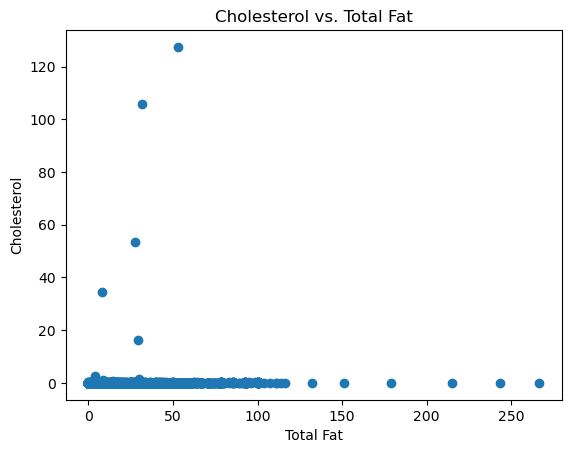

In [29]:
# correlation between fat and cholesterol
plt.scatter(d['Total Fat'], d['Cholesterol'])
plt.xlabel('Total Fat')
plt.ylabel('Cholesterol')
plt.title('Cholesterol vs. Total Fat')
plt.show()

In [30]:
# nutrition between different snack categories
is_snack = d[d['category'].str.contains('snack')]
snack_cat = is_snack.groupby('category').mean(numeric_only=True)
snack_cat

,FPro,FPro_class,price,price percal,package_weight,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
category,,,,,,,,,,,,
snacks-bars,0.802740,2.822397,7.764474,0.009723,269.596229,16.242717,18.523540,51.709138,22.557986,8.678395,0.481686,0.004955
snacks-chips,0.881418,2.949898,3.386820,0.005512,206.490119,8.913645,27.303850,57.907110,4.187794,5.027450,0.643640,0.004384
snacks-dips-salsa,0.757874,2.902870,3.927288,0.014846,335.655866,4.109383,11.767036,13.735908,4.347724,2.843271,0.654074,0.008322
snacks-mixes-crackers,0.880533,2.923835,3.634414,0.005858,280.563932,9.584123,16.541370,63.923872,10.441529,4.110957,0.702245,0.007145
snacks-nuts-seeds,0.606865,2.154062,6.647258,0.005637,330.763690,16.623465,40.055319,33.787450,13.840529,7.557058,0.349343,0.004101
snacks-popcorn,0.861224,2.908654,3.844521,0.005081,312.929563,8.069971,24.573159,57.459231,7.079351,9.747714,0.648949,0.003569


In [48]:
snack_cat_names = snack_cat.index.str.removeprefix('snacks-')
nutrition_cols = ['Protein', 'Total Fat', 'Carbohydrate', 'Sugars, total', 'Fiber, total dietary', 'Sodium', 'Cholesterol']
snacks_nutrition = snack_cat[nutrition_cols].set_index(snack_cat_names)
snacks_nutrition

,Protein,Total Fat,Carbohydrate,"Sugars, total","Fiber, total dietary",Sodium,Cholesterol
category,,,,,,,
bars,16.242717,18.523540,51.709138,22.557986,8.678395,0.481686,0.004955
chips,8.913645,27.303850,57.907110,4.187794,5.027450,0.643640,0.004384
dips-salsa,4.109383,11.767036,13.735908,4.347724,2.843271,0.654074,0.008322
mixes-crackers,9.584123,16.541370,63.923872,10.441529,4.110957,0.702245,0.007145
nuts-seeds,16.623465,40.055319,33.787450,13.840529,7.557058,0.349343,0.004101
popcorn,8.069971,24.573159,57.459231,7.079351,9.747714,0.648949,0.003569


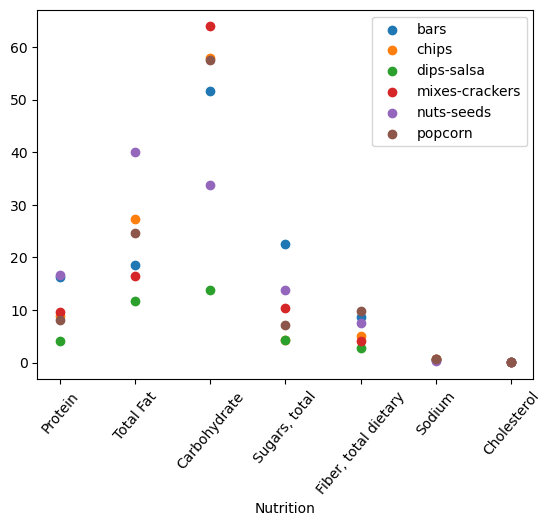

In [49]:
for i in snack_cat_names:
    plt.scatter(nutrition_cols, snacks_nutrition.loc[i], label=i)
    # plt.fill_between(nutrition_cols, snacks_nutrition.loc[i], alpha=0.3)
plt.xlabel('Nutrition')
plt.ylabel('')   #all different units?
plt.legend()
plt.xticks(rotation=50)
plt.show()

In [ ]:
bars = d[d['category']=='snacks-bars']
chips = d[d['category']=='snacks-chips']
dips_salsa = d[d['category']=='snacks-dips-salsa']
mixes_crackers = d[d['category']=='snacks-mixes-crackers']
nuts_seeds = d[d['category']=='snacks-nuts-seeds']
popcorn = d[d['category']=='snacks-popcorn']

# Create a figure with 1 row and 2 columns
fig, ax = plt.subplots(3, 2, figsize=(10, 6))

# First subplot (Scatter plot 1)
ax[0].scatter(x, y1, color='blue', alpha=0.7)
ax[0].set_title('Dataset A')
ax[0].set_xlabel('X Axis')
ax[0].set_ylabel('Y Axis')

# Second subplot (Scatter plot 2)
ax[1].scatter(x, y2, color='red', alpha=0.7)
ax[1].set_title('Dataset B')
ax[1].set_xlabel('X Axis')

# Adjust spacing so labels don't overlap
plt.tight_layout()
plt.show()